# Assignment 07 — ST: forecasting one week of stock volatility with a 5-layer RNN and LSTM

**Dataset:** *S&P 500 Stocks* (andrewmvd, Kaggle): daily open, high, low, close, adjusted close and volume of every S&P 500 member, 2010-01-04 → 2024-12-20 (96 MB CSV, 1.89M rows).
**Task:** from the last $T=40$ trading days of a stock, predict its **average absolute daily move over the next 5 trading days**, $y_t=\frac15\sum_{k=1}^{5}\lvert r_{t+k}\rvert$ (a one-week volatility forecast).

**Why volatility and not the price direction?** Daily returns are close to a random walk: yesterday's return says almost nothing about tomorrow's sign. The *size* of the moves is different: calm days follow calm days and turbulent days follow turbulent days (**volatility clustering**, §3). So there is temporal structure to learn, and a fair test of whether a model with a longer memory (LSTM) uses it better than a plain RNN.
**Why a 5-day average and not tomorrow only?** One day's $\lvert r\rvert$ is a very noisy target: the same calm market can produce a 0.2 % move one day and a 2 % move the next. Averaging five days keeps the signal (the level of turbulence) and removes much of the noise, so differences between models become visible instead of being buried in noise.

**Models:** {5-layer RNN, 5-layer LSTM} × {Keras, PyTorch}, 32 units per layer, linear output. Run IDs `ST-TF-RNN`, `ST-TF-LSTM`, `ST-PT-RNN`, `ST-PT-LSTM`. Structures: `00_rnn_lstm_concepts.ipynb`.

## 1. Setup

Same rules for every run: the same window arrays, architecture, Adam (lr $2\cdot10^{-3}$, clip-norm 1), batch 512, at most 12 epochs, early stopping with patience 3 on the validation loss (best epoch kept), seed 2024.

In [1]:
import os, time, json, random, warnings
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
warnings.filterwarnings("ignore")

SEED = 2024
random.seed(SEED); np.random.seed(SEED)
DATA = Path("../dataset/st")
RES = Path("results"); RES.mkdir(parents=True, exist_ok=True)
IMG = Path("../report/images"); IMG.mkdir(parents=True, exist_ok=True)

T, HZ, H, LAYERS = 40, 5, 32, 5                       # window, forecast horizon (days), units, layers
BATCH, LR, CLIP = 512, 2e-3, 1.0
EPOCHS, PATIENCE = 12, 3
CUT_VALID, CUT_TEST = pd.Timestamp("2019-01-01"), pd.Timestamp("2022-01-01")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("results ->", RES.resolve())

results -> E:\CODING\IS_AI\intelligent_system_assignments\assignment_07\notebook\results


### Hyperparameters

| Name | Value | Meaning |
|---|---|---|
| stocks | all with the full 2010–2024 history | stocks that joined or left the index later are left out, so every stock covers the same dates |
| window $T$ | 40 trading days | about two months of history per prediction |
| horizon | 5 trading days | the target is the mean $\lvert r\rvert$ of days $t+1..t+5$ |
| features $F$ | 5 per day | log return, high–low range, open–close return, log volume, market return (all z-scored) |
| target | $\frac15\sum_{k=1}^5\lvert r_{t+k}\rvert$ | z-scored with train statistics |
| hidden units $H$ | 32 per layer, 5 layers | |
| loss | mean squared error on the standardised target | |
| optimizer | Adam, lr $2\cdot10^{-3}$, clip-norm 1 | |
| split | by calendar: train → 2018, valid 2019–2021, test 2022–2024 | the same cut dates for every stock; a window belongs to the split of the day its target ends |

## 2. Data

The file is in *long* format: one row per (date, stock). Rows before a company joined the index are empty, so only stocks with a **complete** history are kept (ordered by mean dollar volume).

In [2]:
raw = pd.read_csv(DATA / "sp500_stocks.csv", parse_dates=["Date"])
print("raw rows:", f"{len(raw):,}", "| stocks:", raw.Symbol.nunique(), "| dates:", raw.Date.min().date(), "->", raw.Date.max().date())
display(raw.dropna().head(3))
print("empty price rows:", f"{raw.Close.isna().sum():,}")

raw rows: 1,891,536 | stocks: 502 | dates: 2010-01-04 -> 2024-12-20


,Date,Symbol,Adj Close,Close,High,Low,Open,Volume
3768,2010-01-04,AOS,5.937266,7.435000,7.480000,7.261667,7.295000,1104600.0
3769,2010-01-05,AOS,5.861404,7.340000,7.431667,7.308333,7.431667,1207200.0
3770,2010-01-06,AOS,5.864068,7.343333,7.405000,7.301667,7.335000,663000.0


empty price rows: 1,273,705


In [3]:
px = raw.dropna(subset=["Close", "Open", "High", "Low", "Volume", "Adj Close"])
px = px[(px.Close > 0) & (px.Volume > 0)]
n_days = px.Date.nunique()
full = px.groupby("Symbol").Date.count()
full = full[full == n_days].index
dollar_vol = (px[px.Symbol.isin(full)].assign(dv=lambda d: d.Close * d.Volume).groupby("Symbol").dv.mean().sort_values(ascending=False))
TICKERS = list(dollar_vol.index)                                   # all stocks with the full history, most traded first
px = px[px.Symbol.isin(TICKERS)].sort_values(["Symbol", "Date"]).reset_index(drop=True)
print(f"{len(full)} of {raw.Symbol.nunique()} stocks have all {n_days} trading days; all {len(TICKERS)} are used. Most traded:")
print(", ".join(TICKERS[:15]), "...")

145 of 502 stocks have all 3768 trading days; all 145 are used. Most traded:
NVDA, AMZN, MSFT, GOOG, NFLX, C, V, DIS, CSCO, CVX, T, CRM, ORCL, MRK, CMCSA ...


### Features and target, step by step

For stock $s$ on day $t$ (the adjusted close $P_t$ accounts for splits and dividends):

| Feature | Formula | Example |
|---|---|---|
| log return | $r_t=\ln(P_t/P_{t-1})$ | $P$: 100 → 102 gives $\ln1.02=0.0198$ (≈ +2 %) |
| high–low range | $(\text{High}-\text{Low})/\text{Close}$ | high 103, low 99, close 102 → 0.039 |
| open–close return | $\ln(\text{Close}/\text{Open})$ | open 101, close 102 → 0.0098 |
| log volume | $\ln(\text{Volume})$, z-scored per stock with train statistics | |
| market return | the mean of $r_t$ over all stocks on day $t$ | a day on which most stocks fall by 3 % gives ≈ −0.03 |
| **target** | $y_t=\frac15\sum_{k=1}^{5}\lvert r_{t+k}\rvert$ | next five moves 1 %, 3 %, 0.5 %, 2 %, 1.5 % → 1.6 % |

The log return is used because log returns add up over days and a +2 % and a −2 % move have the same size. The **market return** is the one feature that is not about the stock itself: when the whole market moves, individual stocks follow, and a market-wide shock is the main reason for turbulence to spread. It uses only day-$t$ information, so it does not look into the future.

In [4]:
px["ret"] = px.groupby("Symbol")["Adj Close"].transform(lambda s: np.log(s).diff())
px["hl"] = (px.High - px.Low) / px.Close
px["oc"] = np.log(px.Close / px.Open)
px["lvol"] = np.log(px.Volume)
px["mkt"] = px.groupby("Date").ret.transform("mean")
px["absr"] = px.ret.abs()
g = px.groupby("Symbol")
px["target"] = g.absr.transform(lambda s: s.rolling(HZ).mean().shift(-HZ))       # mean |r| over t+1..t+HZ
px["tend"] = g.Date.shift(-HZ)                                                    # the day on which the target window ends
px["base_5"] = g.absr.transform(lambda s: s.rolling(5).mean())                    # baselines use the past only
px["base_20"] = g.absr.transform(lambda s: s.rolling(20).mean())
px["base_ewma"] = g.absr.transform(lambda s: s.ewm(alpha=0.06, adjust=False).mean())
px = px.dropna(subset=["ret"]).reset_index(drop=True)
print("train  : target ends before", CUT_VALID.date()); print("valid  :", CUT_VALID.date(), "->", (CUT_TEST - pd.Timedelta(days=1)).date()); print("test   :", CUT_TEST.date(), "->", px.Date.max().date())
display(px[px.Symbol == TICKERS[0]].iloc[1:4][["Date", "Symbol", "Adj Close", "ret", "hl", "oc", "lvol", "mkt", "target"]])

train  : target ends before 2019-01-01
valid  : 2019-01-01 -> 2021-12-31
test   : 2022-01-01 -> 2024-12-20


,Date,Symbol,Adj Close,ret,hl,oc,lvol,mkt,target
357866,2010-01-06,NVDA,0.432864,0.006376,0.018538,0.006909,20.291202,0.004276,0.016809
357867,2010-01-07,NVDA,0.424381,-0.019792,0.026472,-0.014481,20.121406,0.005032,0.016002
357868,2010-01-08,NVDA,0.425298,0.002159,0.023181,0.010295,19.985473,0.002422,0.021558


## 3. Exploratory data analysis

Three plots: (1) prices of a few stocks with the split dates; (2) the distribution of daily returns, which has **fat tails** (big moves are far more common than a normal distribution predicts); (3) the key plot for this task: how strongly $r_t$, $\lvert r_t\rvert$ and the market return depend on their own past.

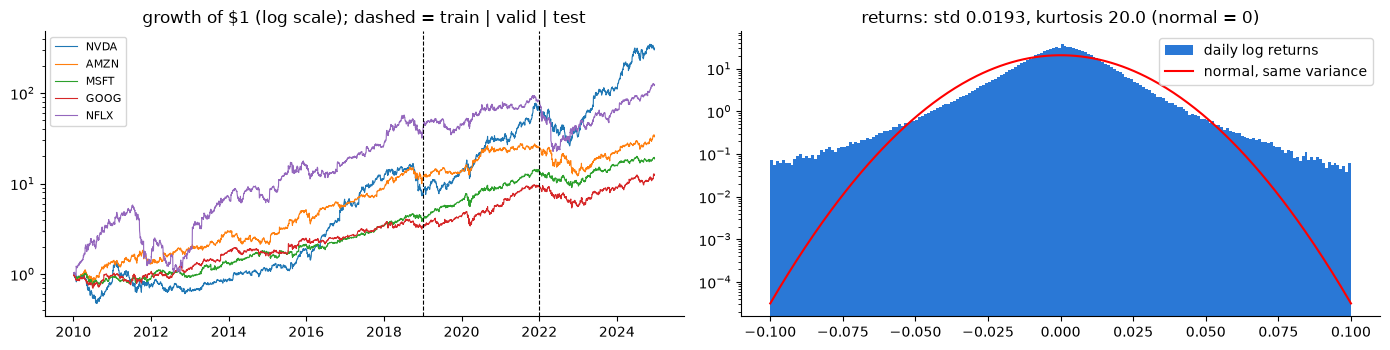

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
for s in TICKERS[:5]:
    d = px[px.Symbol == s]; ax[0].plot(d.Date, d["Adj Close"] / d["Adj Close"].iloc[0], lw=0.8, label=s)
for c in (CUT_VALID, CUT_TEST): ax[0].axvline(c, c="k", ls="--", lw=0.8)
ax[0].set_yscale("log"); ax[0].set_title("growth of $1 (log scale); dashed = train | valid | test"); ax[0].legend(fontsize=8)
r = px.ret.values
ax[1].hist(r, bins=200, range=(-0.1, 0.1), density=True, color="#2a78d6", label="daily log returns")
xx = np.linspace(-0.1, 0.1, 400); ax[1].plot(xx, np.exp(-xx**2 / (2 * r.var())) / np.sqrt(2 * np.pi * r.var()), "r", label="normal, same variance")
ax[1].set_yscale("log"); ax[1].legend(); ax[1].set_title(f"returns: std {r.std():.4f}, kurtosis {pd.Series(r).kurt():.1f} (normal = 0)")
plt.tight_layout(); plt.savefig(IMG / "ST_eda.png", bbox_inches="tight"); plt.show()

### Volatility clustering: why $\lvert r\rvert$ is predictable and $r$ is not

The autocorrelation at lag $k$, $\rho_k=\mathrm{corr}(z_t,z_{t-k})$, measures how much today resembles $k$ days ago. For returns $r_t$ it is ≈ 0 at every lag (no memory of direction). For absolute returns $\lvert r_t\rvert$ it is clearly positive and decays **slowly over many weeks**. The right panel shows the consequence for our target, at equal distance in time: a weekly average (computed on **non-overlapping** 5-day blocks, so that no day is counted twice) is far more strongly tied to the previous weeks than a single day is to the day 5, 10, ... days earlier. The weekly level is therefore the more forecastable quantity.

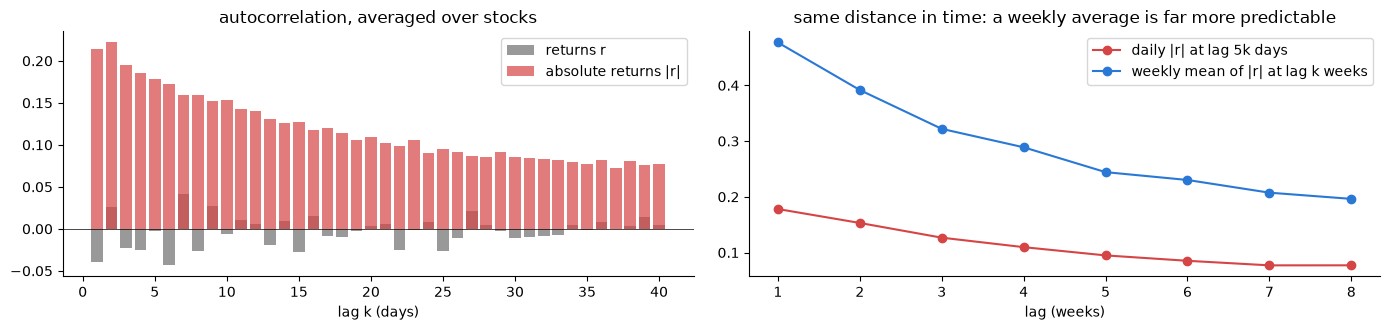

lag-1 autocorrelation: r = -0.040   |r| (daily) = 0.215
one week apart: daily |r| = 0.178   weekly mean |r| (non-overlapping blocks) = 0.477
eight weeks apart: daily |r| = 0.077   weekly mean |r| = 0.196


In [6]:
def acf(x, lags):
    x = x - x.mean(); v = (x * x).mean()
    return np.array([(x[k:] * x[:-k]).mean() / v for k in lags])
lags = np.arange(1, 41)
by = {s: d for s, d in px.groupby("Symbol")}
a_r = np.mean([acf(by[s].ret.values, lags) for s in TICKERS], 0)
a_abs = np.mean([acf(by[s].absr.values, lags) for s in TICKERS], 0)
wk_lags = np.arange(1, 9)                                     # lags in weeks; the weekly series uses NON-overlapping blocks of 5 days
def weekly(x): n = len(x) // HZ * HZ; return x[:n].reshape(-1, HZ).mean(1)
a_wk = np.mean([acf(weekly(by[s].absr.values), wk_lags) for s in TICKERS], 0)
a_day_at_wk = a_abs[wk_lags * HZ - 1]                          # the daily |r| at the same distance (5, 10, ... days)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.4))
ax[0].bar(lags, a_r, color="#999", label="returns r"); ax[0].bar(lags, a_abs, color="#d64545", alpha=0.7, label="absolute returns |r|")
ax[0].axhline(0, c="k", lw=0.5); ax[0].set_xlabel("lag k (days)"); ax[0].set_title("autocorrelation, averaged over stocks"); ax[0].legend()
ax[1].plot(wk_lags, a_day_at_wk, "o-", c="#d64545", label="daily |r| at lag 5k days"); ax[1].plot(wk_lags, a_wk, "o-", c="#2a78d6", label="weekly mean of |r| at lag k weeks")
ax[1].set_xlabel("lag (weeks)"); ax[1].set_title("same distance in time: a weekly average is far more predictable"); ax[1].legend()
plt.tight_layout(); plt.savefig(IMG / "ST_clustering.png", bbox_inches="tight"); plt.show()
print("lag-1 autocorrelation: r = %.3f   |r| (daily) = %.3f" % (a_r[0], a_abs[0]))
print("one week apart: daily |r| = %.3f   weekly mean |r| (non-overlapping blocks) = %.3f" % (a_day_at_wk[0], a_wk[0]))
print("eight weeks apart: daily |r| = %.3f   weekly mean |r| = %.3f" % (a_day_at_wk[-1], a_wk[-1]))

## 4. Windows, scaling and baselines

**Scaling.** Features and target are z-scored, $z=(x-\mu)/\sigma$, with $\mu,\sigma$ computed on the **train period only** (log volume per stock, the other features over all stocks). Statistics from the test period would leak the future.

**Windows.** For each stock the $F=5$ daily features become overlapping windows: days $t-39..t$ are the input, $y_t$ is the target. A window belongs to train, validation or test by the day its **target ends** ($t+5$). With a 5-day target this matters: a window ending on the last train day has a target that reaches into the validation period, and it is dropped from train. No target ever crosses a split boundary. (The *input* of a validation or test window may look back into the previous period, as it would in real use.)
Example with $T=3$ and a 2-day target: features of days 1, 2, 3 → target $\frac12(\lvert r_4\rvert+\lvert r_5\rvert)$; days 2, 3, 4 → $\frac12(\lvert r_5\rvert+\lvert r_6\rvert)$.

In [7]:
FEATS = ["ret", "hl", "oc", "lvol", "mkt"]
tr_rows = px.tend < CUT_VALID
lvol_mean = px[tr_rows].groupby("Symbol").lvol.mean(); lvol_std = px[tr_rows].groupby("Symbol").lvol.std()
px["lvol"] = (px.lvol - px.Symbol.map(lvol_mean)) / px.Symbol.map(lvol_std)
mu = px.loc[tr_rows, ["ret", "hl", "oc", "mkt"]].mean(); sd = px.loc[tr_rows, ["ret", "hl", "oc", "mkt"]].std()
for f in ["ret", "hl", "oc", "mkt"]: px[f] = (px[f] - mu[f]) / sd[f]
y_mu, y_sd = px.loc[tr_rows, "target"].mean(), px.loc[tr_rows, "target"].std()

parts = {k: [] for k in ["X", "y", "tend", "base_5", "base_20", "base_ewma", "sym"]}
for s in TICKERS:
    d = px[px.Symbol == s]
    F = d[FEATS].values.astype("float32")
    X = sliding_window_view(F, T, axis=0).transpose(0, 2, 1)         # (n-T+1, T, F): window i = days i..i+T-1
    last = np.arange(T - 1, len(d))                                                   # index of the last input day of each window
    ok = ~np.isnan(d.target.values[last])                                             # the last HZ days have no full target
    parts["X"].append(np.ascontiguousarray(X[ok])); parts["y"].append(d.target.values[last][ok].astype("float32"))
    parts["tend"].append(d.tend.values[last][ok])
    for k in ["base_5", "base_20", "base_ewma"]: parts[k].append(d[k].values[last][ok])
    parts["sym"].append(np.full(ok.sum(), s))
A = {k: np.concatenate(v) for k, v in parts.items()}
split = np.where(A["tend"] < np.datetime64(CUT_VALID), 0, np.where(A["tend"] < np.datetime64(CUT_TEST), 1, 2))
ys = (A["y"] - y_mu) / y_sd                                                           # standardised target
Xtr, Xva, Xte = (A["X"][split == i] for i in range(3))
ytr, yva = ys[split == 0], ys[split == 1]
yte = A["y"][split == 2]                                                              # test target in original units
print(f"windows: train {len(Xtr):,}  valid {len(Xva):,}  test {len(Xte):,}   X shape {Xtr.shape} = (windows, T, F)")
print("test windows come from", pd.Timestamp(A["tend"][split == 2].min()).date(), "to", pd.Timestamp(A["tend"][split == 2].max()).date())

windows: train 321,755  valid 109,765  test 108,315   X shape (321755, 40, 5) = (windows, T, F)
test windows come from 2022-01-03 to 2024-12-20


### Metrics and baselines

Errors are reported in the original unit (mean absolute daily log return, shown in %): RMSE $=\sqrt{\frac1N\sum(y-\hat y)^2}$, MAE $=\frac1N\sum\lvert y-\hat y\rvert$, the out-of-sample $R^2=1-\frac{\sum(y-\hat y)^2}{\sum(y-\bar y_{\text{train}})^2}$ (0 = no better than always predicting the train mean, negative = worse) and the correlation between forecast and truth.

Baselines a model must beat (all use only the past):
- **train mean**: always predict the average target of the train period;
- **last 5 days**: the mean $\lvert r\rvert$ of the last 5 days (a persistence forecast for a weekly target);
- **last 20 days**: the mean $\lvert r\rvert$ of the last 20 days (a classical volatility estimate);
- **EWMA**: an exponentially weighted average of $\lvert r\rvert$ with weight 0.94 on the past (the RiskMetrics rule used by banks): $\sigma_t=0.94\,\sigma_{t-1}+0.06\,\lvert r_t\rvert$. It is a hand-built recurrent model with one number of state, which makes it the natural opponent of a learned recurrent network.

In [8]:
RUNS = {}
def metrics(y, p):
    e = y - p
    return dict(rmse=float(np.sqrt((e ** 2).mean())), mae=float(np.abs(e).mean()),
                r2_oos=float(1 - (e ** 2).sum() / ((y - y_mu) ** 2).sum()), corr=float(np.corrcoef(y, p)[0, 1]))
BASE = {"train mean": metrics(yte, np.full_like(yte, y_mu)),
        "last 5 days": metrics(yte, A["base_5"][split == 2]),
        "last 20 days": metrics(yte, A["base_20"][split == 2]),
        "EWMA 0.94": metrics(yte, A["base_ewma"][split == 2])}
display((pd.DataFrame(BASE).T * [100, 100, 1, 1]).rename(columns={"rmse": "RMSE (%)", "mae": "MAE (%)"}).round(4))

def finalize(run_id, p_std, history, params, sec_epoch, total_s):
    p = p_std * y_sd + y_mu                                                  # back to original units
    rec = dict(run_id=run_id, params=int(params), sec_per_epoch=round(sec_epoch, 2), train_seconds=round(total_s, 1),
               epochs=len(history["loss"]), best_epoch=int(np.argmin(history["val_loss"]) + 1), history=history, **metrics(yte, p))
    RUNS[run_id] = {**rec, "pred": p}
    json.dump(rec, open(RES / f"{run_id}.json", "w"), indent=1)
    print(f"{run_id}: RMSE {100 * rec['rmse']:.4f}%  MAE {100 * rec['mae']:.4f}%  R2 {rec['r2_oos']:.4f}  corr {rec['corr']:.3f}  "
          f"epochs {rec['epochs']} (best {rec['best_epoch']})  {sec_epoch:.0f} s/epoch")

NF = len(FEATS)
def rnn_params(F, H, L, nb=1):  return F * H + H * H + nb * H + (L - 1) * (2 * H * H + nb * H)
EXPECTED = {"RNN": rnn_params(NF, H, LAYERS) + H + 1, "LSTM": 4 * rnn_params(NF, H, LAYERS) + H + 1}
print("expected parameters (Keras-style):", EXPECTED)

,RMSE (%),MAE (%),r2_oos,corr
train mean,0.8307,0.5613,0.0000,NaN
last 5 days,0.8819,0.6175,-0.1272,0.4039
last 20 days,0.7332,0.5174,0.2210,0.4854
EWMA 0.94,0.6969,0.4894,0.2961,0.5261


expected parameters (Keras-style): {'RNN': 9569, 'LSTM': 38177}


**Reading the baselines.** The mean of the last 5 days is a noisy copy of next week's level; averaging 20 days removes more noise; the EWMA weights recent days more and old days less without a hard cut-off. The recurrent networks have to beat the EWMA to show that they learned something beyond a smoothing rule with one tuned constant.

## 5. Keras — runs `ST-TF-RNN`, `ST-TF-LSTM`

`Input((40, 5))` → 4 recurrent layers returning sequences → 1 returning its last state → `Dense(1)` with no activation (a regression output). Parameter count, RNN: layer 1 $5\cdot32+32\cdot32+32=1{,}216$, layers 2–5 $2\cdot32^2+32=2{,}080$ each, head 33, total $9{,}569$; LSTM: 4× the recurrent part, $38{,}177$.

In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

def build_keras(kind):
    cell = {"RNN": layers.SimpleRNN, "LSTM": layers.LSTM}[kind]
    m = keras.Sequential([layers.Input((T, NF))] + [cell(H, return_sequences=(l < LAYERS - 1)) for l in range(LAYERS)] + [layers.Dense(1)],
                         name=f"keras_{kind}")
    m.compile(optimizer=keras.optimizers.Adam(LR, clipnorm=CLIP), loss="mse")
    return m

class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self.t = time.time()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.time() - self.t)

def run_keras(kind):
    tf.keras.utils.set_random_seed(SEED)
    m = build_keras(kind); assert m.count_params() == EXPECTED[kind], (m.count_params(), EXPECTED[kind])
    timer = EpochTimer(); t0 = time.time()
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCHS, batch_size=BATCH, verbose=2,
              callbacks=[keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True), timer])
    p = m.predict(Xte, batch_size=2048, verbose=0)[:, 0]
    finalize(f"ST-TF-{kind}", p, {"loss": h.history["loss"], "val_loss": h.history["val_loss"]}, m.count_params(),
             float(np.median(timer.times[1:] or timer.times)), time.time() - t0)

build_keras("LSTM").summary()

TensorFlow 2.21.0 | GPUs: []


Model: "keras_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 40, 32)         │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 40, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 40, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 40, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,177 (149.13 KB)

 Trainable params: 38,177 (149.13 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
run_keras("RNN")

Epoch 1/12


629/629 - 23s - 36ms/step - loss: 0.6092 - val_loss: 1.8199


Epoch 2/12


629/629 - 19s - 30ms/step - loss: 0.5322 - val_loss: 1.8871


Epoch 3/12


629/629 - 22s - 35ms/step - loss: 0.4957 - val_loss: 1.9207


Epoch 4/12


629/629 - 20s - 32ms/step - loss: 0.4745 - val_loss: 1.9950


ST-TF-RNN: RMSE 0.6849%  MAE 0.4821%  R2 0.3203  corr 0.533  epochs 4 (best 1)  20 s/epoch


In [11]:
run_keras("LSTM")

Epoch 1/12


629/629 - 96s - 152ms/step - loss: 0.6112 - val_loss: 1.8136


Epoch 2/12


629/629 - 86s - 137ms/step - loss: 0.5439 - val_loss: 1.8696


Epoch 3/12


629/629 - 87s - 138ms/step - loss: 0.5142 - val_loss: 1.9644


Epoch 4/12


629/629 - 86s - 136ms/step - loss: 0.4866 - val_loss: 2.0565


ST-TF-LSTM: RMSE 0.6788%  MAE 0.4758%  R2 0.3323  corr 0.544  epochs 4 (best 1)  86 s/epoch


## 6. PyTorch — runs `ST-PT-RNN`, `ST-PT-LSTM`

`nn.RNN(5, 32, num_layers=5, batch_first=True)` / `nn.LSTM(...)` → last step of the top layer → `nn.Linear(32, 1)`, with Keras's initialisation (Glorot input weights, orthogonal recurrent weights, zero biases, LSTM forget bias 1) so both frameworks start alike. PyTorch's second bias vector adds $5\cdot32=160$ (RNN) or $5\cdot128=640$ (LSTM) parameters, all starting at zero.

In [12]:
import torch, torch.nn as nn
torch.manual_seed(SEED)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", DEV)

class TorchVol(nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM}[kind](NF, H, num_layers=LAYERS, batch_first=True)
        self.head = nn.Linear(H, 1)
        blocks = 4 if kind == "LSTM" else 1
        for name, p in self.rnn.named_parameters():
            if name.startswith("weight_ih"):
                for blk in p.data.chunk(blocks): nn.init.xavier_uniform_(blk)
            elif name.startswith("weight_hh"):
                for blk in p.data.chunk(blocks): nn.init.orthogonal_(blk)
            else:
                nn.init.zeros_(p)
                if kind == "LSTM" and name.startswith("bias_ih"): p.data[H:2 * H] = 1.0
        nn.init.xavier_uniform_(self.head.weight); nn.init.zeros_(self.head.bias)
    def forward(self, x):                    # x: (B, 40, 5)
        out, _ = self.rnn(x)
        return self.head(out[:, -1]).squeeze(1)

def predict_torch(m, X, bs=4096):
    m.eval()
    with torch.no_grad():
        return np.concatenate([m(torch.from_numpy(X[i:i + bs]).to(DEV)).cpu().numpy() for i in range(0, len(X), bs)])

def run_torch(kind):
    torch.manual_seed(SEED)
    m = TorchVol(kind).to(DEV); n = sum(p.numel() for p in m.parameters())
    assert n == EXPECTED[kind] + LAYERS * H * (4 if kind == "LSTM" else 1)
    opt = torch.optim.Adam(m.parameters(), lr=LR, eps=1e-7); lossf = nn.MSELoss()
    Xt, yt = torch.from_numpy(Xtr), torch.from_numpy(ytr)
    hist = {"loss": [], "val_loss": []}; times = []; best, best_state, wait = np.inf, {k: v.detach().clone() for k, v in m.state_dict().items()}, 0
    g = torch.Generator().manual_seed(SEED); t0 = time.time()
    for ep in range(EPOCHS):
        m.train(); te = time.time(); tot = 0.0
        for b in torch.randperm(len(Xt), generator=g).split(BATCH):
            xb, yb = Xt[b].to(DEV), yt[b].to(DEV)
            loss = lossf(m(xb), yb)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), CLIP); opt.step()
            tot += loss.item() * len(b)
        vl = float(((predict_torch(m, Xva) - yva) ** 2).mean()); times.append(time.time() - te)
        hist["loss"].append(tot / len(Xt)); hist["val_loss"].append(vl)
        print(f"epoch {ep + 1}: loss {hist['loss'][-1]:.4f}  val_loss {vl:.4f}  {times[-1]:.0f}s")
        if vl < best - 1e-4:
            best, wait = vl, 0; best_state = {k: v.detach().clone() for k, v in m.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE: break
    m.load_state_dict(best_state)
    finalize(f"ST-PT-{kind}", predict_torch(m, Xte), hist, n, float(np.median(times[1:] or times)), time.time() - t0)

print(TorchVol("RNN"))

PyTorch 2.14.1+cpu | device: cpu
TorchVol(
  (rnn): RNN(5, 32, num_layers=5, batch_first=True)
  (head): Linear(in_features=32, out_features=1, bias=True)
)


In [13]:
run_torch("RNN")

epoch 1: loss 0.6171  val_loss 1.7755  31s


epoch 2: loss 0.5570  val_loss 1.8757  30s


epoch 3: loss 0.5231  val_loss 1.7954  32s


epoch 4: loss 0.4987  val_loss 1.8518  31s


ST-PT-RNN: RMSE 0.6956%  MAE 0.5005%  R2 0.2988  corr 0.516  epochs 4 (best 1)  31 s/epoch


In [14]:
run_torch("LSTM")

epoch 1: loss 0.6011  val_loss 1.7822  61s


epoch 2: loss 0.5353  val_loss 1.9436  65s


epoch 3: loss 0.5035  val_loss 1.9446  68s


epoch 4: loss 0.4763  val_loss 1.9642  66s


ST-PT-LSTM: RMSE 0.6828%  MAE 0.4838%  R2 0.3245  corr 0.540  epochs 4 (best 1)  66 s/epoch


## 7. Comparison

In [15]:
rows = [{"run": k, **{m: v[m] for m in ["rmse", "mae", "r2_oos", "corr", "params", "sec_per_epoch", "epochs", "best_epoch"]}} for k, v in RUNS.items()]
rows += [{"run": f"baseline: {k}", **v} for k, v in BASE.items()]
table = pd.DataFrame(rows).set_index("run")
table[["rmse", "mae"]] *= 100
table = table.rename(columns={"rmse": "RMSE (%)", "mae": "MAE (%)"})
table.to_csv(RES / "ST_comparison.csv")
display(table.round(4))

,RMSE (%),MAE (%),r2_oos,corr,params,sec_per_epoch,epochs,best_epoch
run,,,,,,,,
ST-TF-RNN,0.6849,0.4821,0.3203,0.5327,9569.0,20.16,4.0,1.0
ST-TF-LSTM,0.6788,0.4758,0.3323,0.5438,38177.0,86.48,4.0,1.0
ST-PT-RNN,0.6956,0.5005,0.2988,0.5158,9729.0,31.13,4.0,1.0
ST-PT-LSTM,0.6828,0.4838,0.3245,0.5395,38817.0,66.32,4.0,1.0
baseline: train mean,0.8307,0.5613,0.0000,NaN,NaN,NaN,NaN,NaN
baseline: last 5 days,0.8819,0.6175,-0.1272,0.4039,NaN,NaN,NaN,NaN
baseline: last 20 days,0.7332,0.5174,0.2210,0.4854,NaN,NaN,NaN,NaN
baseline: EWMA 0.94,0.6969,0.4894,0.2961,0.5261,NaN,NaN,NaN,NaN


### Learning curves

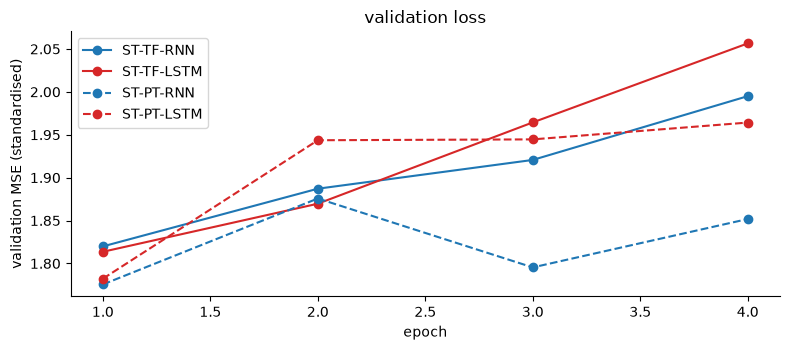

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, v in RUNS.items():
    ax.plot(range(1, len(v["history"]["val_loss"]) + 1), v["history"]["val_loss"], "-" if "-TF-" in k else "--",
            c="C0" if k.endswith("RNN") else "C3", marker="o", label=k)
ax.set_xlabel("epoch"); ax.set_ylabel("validation MSE (standardised)"); ax.legend(); ax.set_title("validation loss")
plt.tight_layout(); plt.savefig(IMG / "ST_curves.png", bbox_inches="tight"); plt.show()

### Forecast against truth

The last 250 test days of one stock from the middle of the liquidity ranking: the true weekly volatility $y_t$ (grey), the EWMA baseline and the Keras RNN and LSTM forecasts. A volatility forecast cannot say which day will move; a good one rises and falls with the level of turbulence.

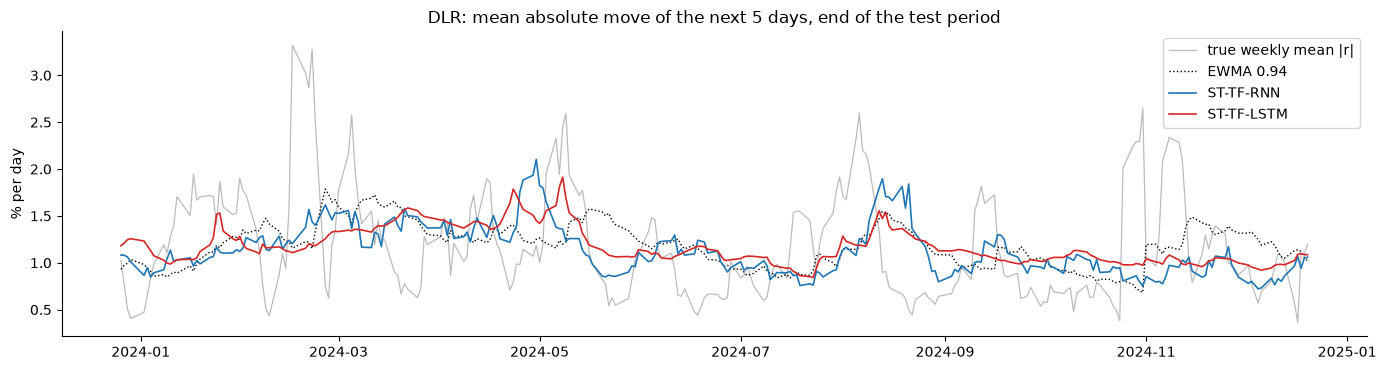

In [17]:
s0 = TICKERS[len(TICKERS) // 2]; mask = A["sym"][split == 2] == s0
dt = A["tend"][split == 2][mask][-250:]
plt.figure(figsize=(14, 3.8))
plt.plot(dt, 100 * yte[mask][-250:], c="#bbb", lw=0.9, label="true weekly mean |r|")
plt.plot(dt, 100 * A["base_ewma"][split == 2][mask][-250:], c="k", lw=1, ls=":", label="EWMA 0.94")
for k, c in [("ST-TF-RNN", "C0"), ("ST-TF-LSTM", "C3")]:
    if k in RUNS: plt.plot(dt, 100 * RUNS[k]["pred"][mask][-250:], c=c, lw=1.2, label=k)
plt.ylabel("% per day"); plt.title(f"{s0}: mean absolute move of the next 5 days, end of the test period"); plt.legend()
plt.tight_layout(); plt.savefig(IMG / "ST_forecast.png", bbox_inches="tight"); plt.show()

### Error in calm and turbulent periods

Test windows split into five groups by the 20-day volatility level at prediction time. Memory matters most when the level changes; a model that only follows the last few days should lose more in the most turbulent group.

,ST-TF-RNN,ST-TF-LSTM,ST-PT-RNN,ST-PT-LSTM,EWMA 0.94
calmest,0.5003,0.4911,0.5041,0.4970,0.5111
calm,0.5888,0.5716,0.5924,0.5805,0.5859
middle,0.6503,0.6340,0.6569,0.6406,0.6480
turbulent,0.7003,0.6871,0.7061,0.7008,0.7092
most turbulent,0.9138,0.9284,0.9404,0.9194,0.9493


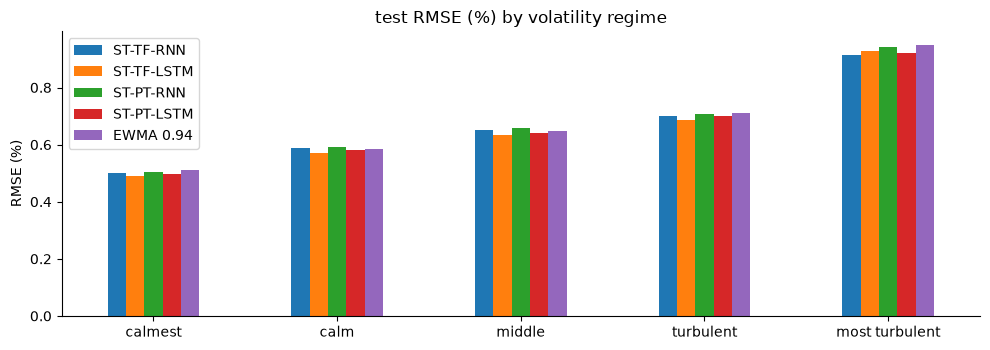

In [18]:
lvl = pd.qcut(A["base_20"][split == 2], 5, labels=["calmest", "calm", "middle", "turbulent", "most turbulent"])
err = pd.DataFrame({k: pd.Series((v["pred"] - yte) ** 2).groupby(lvl).mean() ** 0.5 * 100 for k, v in RUNS.items()})
err["EWMA 0.94"] = pd.Series((A["base_ewma"][split == 2] - yte) ** 2).groupby(lvl).mean() ** 0.5 * 100
display(err.round(4))
err.plot.bar(rot=0, figsize=(10, 3.6), title="test RMSE (%) by volatility regime"); plt.ylabel("RMSE (%)")
plt.tight_layout(); plt.savefig(IMG / "ST_by_regime.png", bbox_inches="tight"); plt.show()

### Error by test year

The three test years are different markets: 2022 was a bear market with rising interest rates, 2023 a calm recovery, 2024 a calm year with short spikes. A forecaster that is good in one regime and bad in another shows up here.

,ST-TF-RNN,ST-TF-LSTM,ST-PT-RNN,ST-PT-LSTM,EWMA 0.94,mean target (%)
2022,0.7644,0.7625,0.7819,0.7678,0.7819,1.6671
2023,0.6372,0.6328,0.6510,0.6422,0.6496,1.2427
2024,0.6446,0.6316,0.6442,0.6284,0.6498,1.1726


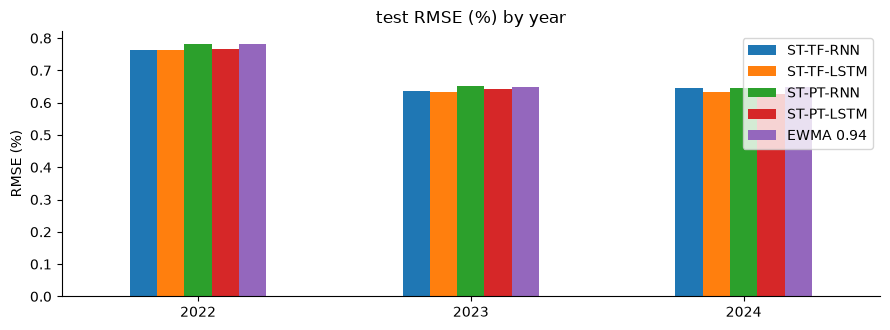

In [19]:
year = pd.DatetimeIndex(A["tend"][split == 2]).year
by_year = pd.DataFrame({k: pd.Series((v["pred"] - yte) ** 2).groupby(year).mean() ** 0.5 * 100 for k, v in RUNS.items()})
by_year["EWMA 0.94"] = pd.Series((A["base_ewma"][split == 2] - yte) ** 2).groupby(year).mean() ** 0.5 * 100
by_year["mean target (%)"] = pd.Series(yte).groupby(year).mean() * 100
display(by_year.round(4))
by_year.drop(columns="mean target (%)").plot.bar(rot=0, figsize=(9, 3.4), title="test RMSE (%) by year"); plt.ylabel("RMSE (%)")
plt.tight_layout(); plt.savefig(IMG / "ST_by_year.png", bbox_inches="tight"); plt.show()

## 8. Conclusion

All numbers are on the same 108,315 test windows (2022–2024, 145 stocks, one run per configuration, seed 2024).

| | RMSE (%) | $R^2$ | corr | s/epoch |
|---|---|---|---|---|
| train mean | 0.831 | 0.000 | — | — |
| last 20 days | 0.733 | 0.221 | 0.485 | — |
| EWMA 0.94 | 0.697 | 0.296 | 0.526 | — |
| RNN (Keras / PyTorch) | 0.685 / 0.696 | 0.320 / 0.299 | 0.533 / 0.516 | 20 / 31 |
| LSTM (Keras / PyTorch) | 0.679 / 0.683 | 0.332 / 0.324 | 0.544 / 0.540 | 86 / 66 |

- **The target is forecastable.** The weekly mean of $\lvert r\rvert$ is much more tied to its own past than a single day is (autocorrelation 0.48 against 0.18 one week apart), and all runs reach $R^2$ of 0.30–0.33 against 0.22 for the last-20-days average.
- **The networks beat the EWMA, by little.** The RMSE gain over the EWMA is 0.2 % (PyTorch RNN) to 2.6 % (Keras LSTM). The EWMA, a hand-built recurrent model with one number of state, is a strong opponent. Both LSTMs beat the EWMA in all five volatility regimes and in all three test years. The RNNs do not: they lose narrowly in the calm and middle regimes, and the PyTorch RNN ties the EWMA in 2022 and is slightly worse in 2023.
- **LSTM against RNN: a small edge that is within the noise.** The LSTM's RMSE is lower by 0.9 % (Keras) and 1.8 % (PyTorch), but the two implementations of the *same* model differ by 1.6 % (RNN) and 0.6 % (LSTM): the LSTM advantage is not larger than the framework-to-framework spread of single runs.
- **Early stopping chose epoch 1 in all four runs.** Validation loss (standardised MSE about 1.8, against about 0.6 on train) is dominated by the 2019–2021 validation period, which contains the March 2020 crash, and rises from epoch 2 on. The reported models are therefore barely trained; a calmer validation period or a longer horizon of patience could change this.
- **Cost.** The LSTM has 4× the parameters (38,177 against 9,569) and takes 2.1× (PyTorch) to 4.3× (Keras) the time per epoch for this small gain.
